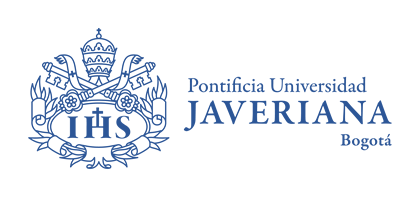
# Aprendizaje Profundo
## Laboratorio — Difusión a pequeña escala

In [1]:
# Paso 1. Librerías: cálculo y azar, manejo de arreglos, gráficas y TensorFlow/Keras.
import math, random, time
import numpy as np
import matplotlib.pyplot as plt
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers

## 0. Preparación y configuración

Se recomienda activar una GPU en Colab. El modo rápido utiliza un subconjunto de MNIST; para obtener resultados mejores, aumenta las épocas y utiliza todos los datos. No hay garantía de que pocas épocas produzcan dígitos nítidos.

In [2]:
# Paso 2. Fijamos la semilla para que los experimentos sean comparables.
SEED = 42
random.seed(SEED)
np.random.seed(SEED)
tf.random.set_seed(SEED)
print('TensorFlow:', tf.__version__, '| GPU:', tf.config.list_physical_devices('GPU'))

# Configuración: un ensayo corto primero; luego ampliar el entrenamiento.
# T: número de pasos de difusión. Beta define cuánto ruido se añade en cada uno.
T = 500
BETA_START, BETA_END = 1e-4, 0.05
# Tamaño del lote, imágenes usadas (subconjunto para ir rápido), épocas y tasa de aprendizaje.
BATCH_SIZE = 128
TRAIN_EXAMPLES = 12000  # None: usar las 60 000 imágenes
EPOCHS = 5
LR = 2e-4
AUTOTUNE = tf.data.AUTOTUNE

TensorFlow: 2.21.0 | GPU: [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]


**Comentario:** Primero se hace un ensayo corto (5 épocas y 12 000 imágenes). Los experimentos de la sección 7 amplían ese entrenamiento.

## 1. MNIST y rango de imágenes

Se descarga el dataset MNIST y se crea un subconjunto de entrenamiento

11490434/11490434 ━━━━━━━━━━━━━━━━━━━━ 2s 0us/step
Forma: (128, 28, 28, 1) | min/max: -1.0 1.0


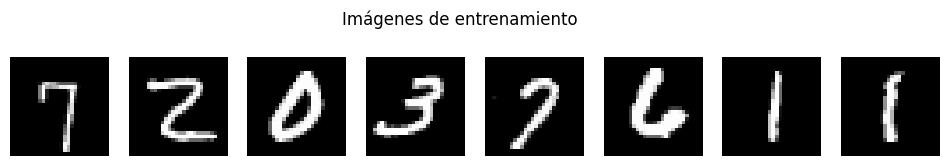

In [3]:
# Paso 3. Cargamos MNIST (solo entrenamiento en esta sección).
(train_images, train_labels), _ = keras.datasets.mnist.load_data()
# Llevamos los píxeles de [0, 255] a [-1, 1], la misma escala aproximada del ruido gaussiano.
train_images = (train_images.astype('float32') / 127.5) - 1.0
# Añadimos el canal: cada imagen queda de 28x28x1.
train_images = train_images[..., None]  # (60000, 28, 28, 1): NHWC
# Elegimos al azar el subconjunto, siempre el mismo por la semilla.
if TRAIN_EXAMPLES is not None:
    indices = np.random.default_rng(SEED).permutation(len(train_images))[:TRAIN_EXAMPLES]
    train_images, train_labels = train_images[indices], train_labels[indices]

# Canal de datos: mezcla las imágenes en cada época y las agrupa en lotes.
train_ds = (tf.data.Dataset.from_tensor_slices(train_images)
            .shuffle(len(train_images), seed=SEED, reshuffle_each_iteration=True)
            .batch(BATCH_SIZE).prefetch(AUTOTUNE))
# Verificación: el rango debe estar cerca de [-1, 1] y las imágenes deben verse bien.
x0 = next(iter(train_ds))
print('Forma:', x0.shape, '| min/max:', float(tf.reduce_min(x0)), float(tf.reduce_max(x0)))
fig, axes = plt.subplots(1, 8, figsize=(12, 2))
for ax, x in zip(axes, x0[:8]):
    ax.imshow(np.clip((x.numpy()[..., 0] + 1) / 2, 0, 1), cmap='gray', vmin=0, vmax=1)
    ax.axis('off')
plt.suptitle('Imágenes de entrenamiento')
plt.show()

**Comentario:** Se esperan valores entre -1 y 1 y dígitos reconocibles. Esta verificación evita entrenar con datos mal escalados.

## 2. Proceso directo: añadir ruido sin simular todos los pasos

Definimos $\alpha_t=1-\beta_t$ y $\bar\alpha_t=\prod_{s=1}^{t}\alpha_s$. Podemos muestrear directamente un estado de ruido arbitrario:

$$q(x_t\mid x_0)=\mathcal N(\sqrt{\bar\alpha_t}\,x_0,(1-\bar\alpha_t)I),$$
$$x_t=\sqrt{\bar\alpha_t}\,x_0+\sqrt{1-\bar\alpha_t}\,\epsilon,\qquad \epsilon\sim\mathcal N(0,I).$$

En el código, `t=0` significa el *primer paso de ruido*, no la imagen limpia. Comprueba que $\bar\alpha_{T}$ sea pequeña: al final esperamos estar cerca de ruido gaussiano puro.

alpha_bar final: 2.9333941711229272e-06


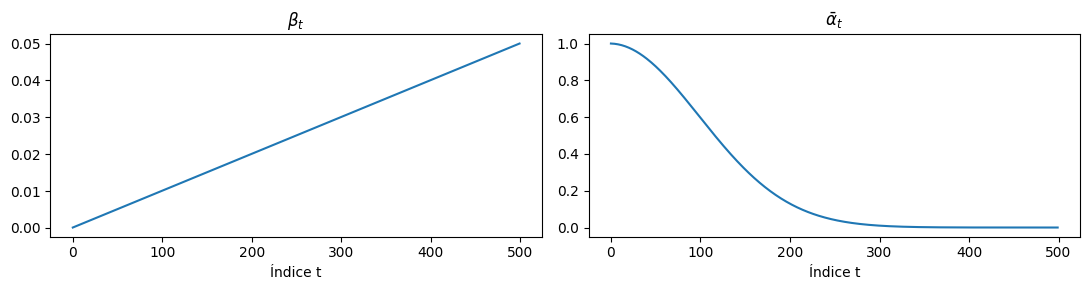

In [4]:
# Paso 4. Calendario lineal de ruido: beta crece de BETA_START a BETA_END.
betas = tf.linspace(tf.constant(BETA_START, tf.float32),
                    tf.constant(BETA_END, tf.float32), T)
alphas = 1.0 - betas
# alpha_bar: fracción acumulada de señal que sobrevive hasta el paso t.
alpha_bars = tf.math.cumprod(alphas)
alpha_bars_prev = tf.concat([tf.ones([1], tf.float32), alpha_bars[:-1]], axis=0)
# Varianza fija que se usará luego en el proceso inverso.
posterior_variance = betas * (1.0 - alpha_bars_prev) / (1.0 - alpha_bars)

def extract(a, t):
    """Extrae el coeficiente del paso t y lo expande a [B,1,1,1]."""
    return tf.reshape(tf.gather(a, t), [-1, 1, 1, 1])

# Fórmula cerrada: salta directo al paso t, sin simular los anteriores.
def q_sample(x_clean, t, noise=None):
    if noise is None:
        noise = tf.random.normal(tf.shape(x_clean), dtype=x_clean.dtype)
    ab = extract(alpha_bars, t)
    return tf.sqrt(ab) * x_clean + tf.sqrt(1.0 - ab) * noise

# Al final casi no debe quedar señal: así el proceso inverso puede partir de ruido puro.
print('alpha_bar final:', float(alpha_bars[-1]))
assert float(alpha_bars[-1]) < 0.02, 'El último paso retiene demasiada señal.'
fig, axs = plt.subplots(1, 2, figsize=(11, 3))
axs[0].plot(betas.numpy()); axs[0].set_title(r'$\beta_t$'); axs[0].set_xlabel('Índice t')
axs[1].plot(alpha_bars.numpy()); axs[1].set_title(r'$\bar{\alpha}_t$'); axs[1].set_xlabel('Índice t')
plt.tight_layout(); plt.show()

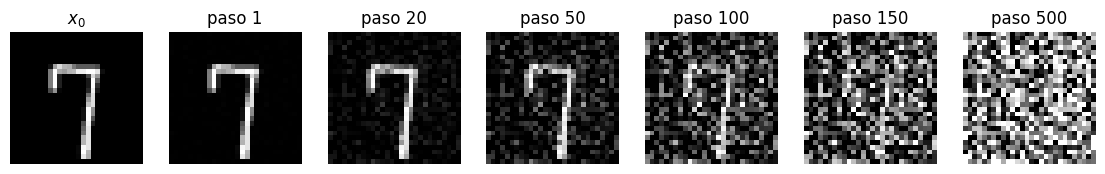

In [5]:
# Misma imagen y mismo epsilon: se aísla el efecto de t.
original = x0[:1]
fixed_noise = tf.random.normal(tf.shape(original))
# Paso 5. Pasos que queremos visualizar; a mayor t, más ruido y menos dígito.
steps = [0, 19, 49, 99, 149, T - 1]
fig, axs = plt.subplots(1, len(steps) + 1, figsize=(14, 2.5))
axs[0].imshow((original[0, :, :, 0].numpy() + 1) / 2, cmap='gray', vmin=0, vmax=1)
axs[0].set_title(r'$x_0$')
for ax, step in zip(axs[1:], steps):
    xt = q_sample(original, tf.constant([step], tf.int32), fixed_noise)
    ax.imshow(np.clip((xt[0, :, :, 0].numpy() + 1)/2, 0, 1), cmap='gray', vmin=0, vmax=1)
    ax.set_title(f'paso {step + 1}')
for ax in axs: ax.axis('off')
plt.show()

**Comentario:** La misma imagen y el mismo ruido se muestran en varios pasos, de modo que el único cambio es `t`. El dígito se va perdiendo hasta quedar solo ruido.



## 3. Modelo de predicción de ruido

El modelo recibe una imagen ruidosa y el instante de difusión. Usaremos una CNN pequeña tipo U-Net con *skip connections*, bloques residuales y embeddings sinusoidales para informar acerca de tiempo t. Es deliberadamente compacta para MNIST; **no** es la arquitectura original completa de DDPM.

In [6]:
# Paso 6. Convierte el número t en un vector: así la red sabe cuánto ruido tiene la imagen.
class SinusoidalTimeEmbedding(layers.Layer):
    def __init__(self, dim=64):
        super().__init__()
        self.dim = dim

    def call(self, t):
        half = self.dim // 2
        freqs = tf.exp(-math.log(10000.0) *
                       tf.cast(tf.range(half), tf.float32) / float(half - 1))
        angles = tf.cast(t[:, None], tf.float32) * freqs[None, :]
        return tf.concat([tf.sin(angles), tf.cos(angles)], axis=-1)

# Bloque residual: dos convoluciones que reciben t y una conexión directa que facilita aprender.
class ResBlock(layers.Layer):
    def __init__(self, out_ch, time_dim):
        super().__init__()
        self.conv1 = layers.Conv2D(out_ch, 3, padding='same')
        self.conv2 = layers.Conv2D(out_ch, 3, padding='same')
        self.norm1 = layers.GroupNormalization(groups=8)
        self.norm2 = layers.GroupNormalization(groups=8)
        self.time_proj = layers.Dense(out_ch)
        self.skip = layers.Conv2D(out_ch, 1, padding='same')

    def call(self, x, emb):
        h = tf.nn.silu(self.norm1(self.conv1(x)))
        # Aquí se inyecta la información del tiempo en los mapas de características.
        h = h + self.time_proj(emb)[:, None, None, :]
        h = tf.nn.silu(self.norm2(self.conv2(h)))
        return h + self.skip(x)

# U-Net pequeña: comprime la imagen (28 -> 14 -> 7) y la reconstruye usando conexiones de salto.
class SmallUNet(keras.Model):
    # base controla el número de filtros, es decir, la capacidad del modelo.
    def __init__(self, base=32, time_dim=128):
        super().__init__()
        self.time_mlp = keras.Sequential([
            SinusoidalTimeEmbedding(64), layers.Dense(time_dim, activation=tf.nn.silu),
            layers.Dense(time_dim)])
        self.init_conv = layers.Conv2D(base, 3, padding='same')
        self.down1 = ResBlock(base, time_dim)                  # 28x28
        self.downsample1 = layers.Conv2D(base, 4, strides=2, padding='same') # 14x14
        self.down2 = ResBlock(base * 2, time_dim)
        self.downsample2 = layers.Conv2D(base * 2, 4, strides=2, padding='same') # 7x7
        self.mid = ResBlock(base * 2, time_dim)
        self.up2 = ResBlock(base, time_dim)
        self.up1 = ResBlock(base, time_dim)
        self.out_conv = layers.Conv2D(1, 3, padding='same')

    def call(self, x, t, training=False):
        emb = self.time_mlp(t)
        h0 = self.init_conv(x)
        h1 = self.down1(h0, emb)
        h2 = self.down2(self.downsample1(h1), emb)
        hm = self.mid(self.downsample2(h2), emb)
        # Subimos resolución y concatenamos con el nivel de bajada para recuperar el detalle.
        u2 = tf.image.resize(hm, tf.shape(h2)[1:3], method='nearest')
        u2 = self.up2(tf.concat([u2, h2], axis=-1), emb)
        u1 = tf.image.resize(u2, tf.shape(h1)[1:3], method='nearest')
        return self.out_conv(self.up1(tf.concat([u1, h1], axis=-1), emb))

# Verificación: la salida debe tener la misma forma de la entrada, porque es el ruido estimado.
model = SmallUNet()
test_out = model(tf.random.normal([2, 28, 28, 1]), tf.constant([0, T - 1], tf.int32))
assert tuple(test_out.shape) == (2, 28, 28, 1)
print('Parámetros:', f'{model.count_params():,}')

Parámetros: 372,417


**Comentario:** La red no genera imágenes directamente: dada una imagen ruidosa y su paso `t`, estima el ruido que contiene.

## 4. Objetivo de entrenamiento

La pérdida simplificada del DDPM (predicción de ruido) es:

$$\mathcal L_{\mathrm{simple}}(\theta)=\mathbb E_{x_0,t,\epsilon}\left[\|\epsilon-\epsilon_\theta(x_t,t)\|_2^2\right].$$

En cada *batch*, se selecciona un $t$ independiente para cada imagen, se genera $x_t$ y la red predice el ruido. `F.mse_loss` promedia sobre los elementos, manteniendo el mismo objetivo salvo por un factor de escala. **No estamos entrenando un autoencoder a reconstruir directamente $x_0$.**

Época 01/5 | MSE: 0.5963
Época 02/5 | MSE: 0.1793
Época 03/5 | MSE: 0.1390
Época 04/5 | MSE: 0.1135
Época 05/5 | MSE: 0.0951
Tiempo de entrenamiento: 0.8 min


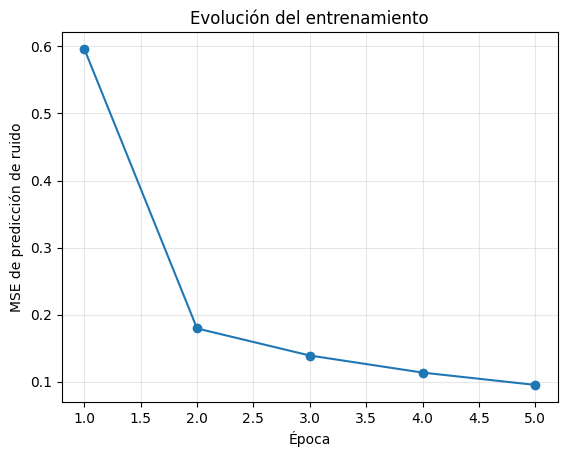

In [7]:
# Paso 7. Adam ajusta los pesos de la red a partir de los gradientes.
optimizer = keras.optimizers.Adam(learning_rate=LR)

@tf.function
def train_step(clean):
    batch_size = tf.shape(clean)[0]
    # Cada imagen del lote recibe su propio paso t al azar.
    t = tf.random.uniform([batch_size], minval=0, maxval=T, dtype=tf.int32)
    # Generamos el ruido real, que es lo que la red debe adivinar.
    noise = tf.random.normal(tf.shape(clean))
    noisy = q_sample(clean, t, noise)
    with tf.GradientTape() as tape:
        predicted_noise = model(noisy, t, training=True)
        # Error cuadrático entre ruido estimado y ruido real (en TensorFlow equivale al F.mse_loss citado arriba).
        loss = tf.reduce_mean(tf.square(predicted_noise - noise))
    grads = tape.gradient(loss, model.trainable_variables)
    optimizer.apply_gradients(zip(grads, model.trainable_variables))
    return loss

# Ciclo de entrenamiento: registra el MSE promedio de cada época.
loss_history = []
start = time.time()
for epoch in range(EPOCHS):
    total_loss, seen = 0.0, 0
    for clean in train_ds:
        loss = train_step(clean)
        n = int(tf.shape(clean)[0])
        total_loss += float(loss) * n
        seen += n
    epoch_loss = total_loss / seen
    loss_history.append(epoch_loss)
    print(f'Época {epoch + 1:02d}/{EPOCHS} | MSE: {epoch_loss:.4f}')
print(f'Tiempo de entrenamiento: {(time.time() - start)/60:.1f} min')
plt.plot(range(1, len(loss_history) + 1), loss_history, marker='o')
plt.xlabel('Época'); plt.ylabel('MSE de predicción de ruido')
plt.title('Evolución del entrenamiento'); plt.grid(alpha=.3); plt.show()

**Comentario:** Si el MSE baja, la red estima mejor el ruido. Es una medida útil pero incompleta: no dice por sí sola si los dígitos generados se ven bien.

## 5. Proceso inverso: generación

Con $\epsilon_\theta(x_t,t)$ estimamos la media de la transición gaussiana inversa:

$$\mu_\theta(x_t,t)=\frac{1}{\sqrt{\alpha_t}}\left(x_t-\frac{\beta_t}{\sqrt{1-\bar\alpha_t}}\epsilon_\theta(x_t,t)\right).$$

Muestreamos $x_{t-1}=\mu_\theta(x_t,t)+\sqrt{\tilde\beta_t}z$, con $z\sim\mathcal N(0,I)$ y $\tilde\beta_t=\beta_t\frac{1-\bar\alpha_{t-1}}{1-\bar\alpha_t}$. En el último paso (hacia $x_0$) no añadimos ruido. Aquí utilizamos la **varianza posterior fija** del DDPM; no se aprende con la red.

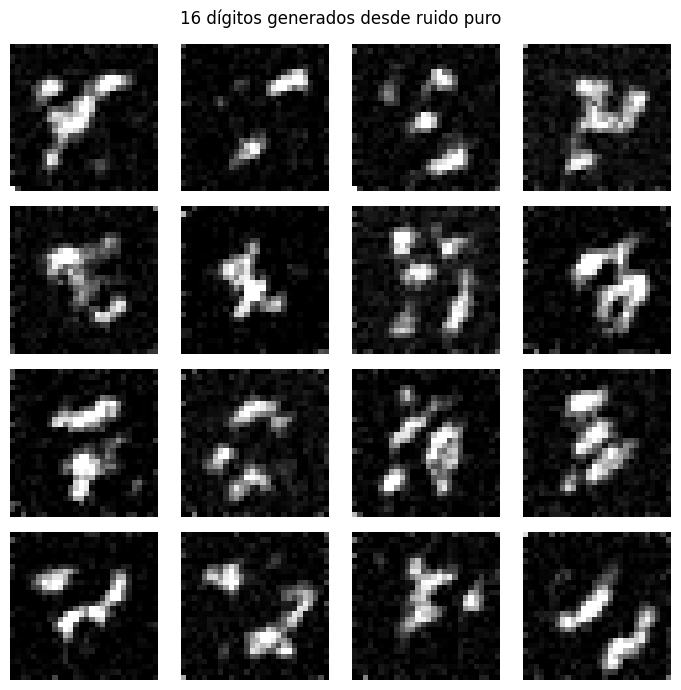

In [8]:
# Paso 8. Un paso inverso: usa el ruido estimado para quitar un poco de ruido a la imagen.
def p_sample(x, index):
    """Una transición inversa de DDPM; index=0 es el último paso."""
    t = tf.fill([tf.shape(x)[0]], tf.cast(index, tf.int32))
    beta_t = extract(betas, t)
    alpha_t = extract(alphas, t)
    ab_t = extract(alpha_bars, t)
    predicted_noise = model(x, t, training=False)
    # Media de la transición inversa (fórmula de la sección 5).
    mean = (x - beta_t / tf.sqrt(1.0 - ab_t) * predicted_noise) / tf.sqrt(alpha_t)
    # En el último paso no se añade ruido: el resultado es la imagen final.
    if index == 0:
        return mean
    # En los demás pasos se añade algo de azar; esto da variedad a las muestras.
    variance = extract(posterior_variance, t)
    return mean + tf.sqrt(variance) * tf.random.normal(tf.shape(x))

# Parte de ruido puro y aplica T pasos inversos; guarda algunos estados intermedios.
def generate(n=16, saved_at=(199, 149, 99, 49, 0), initial_noise=None):
    x = tf.random.normal([n, 28, 28, 1]) if initial_noise is None else tf.identity(initial_noise)
    states = {'inicio (ruido)': x.numpy()}
    for index in reversed(range(T)):
        x = p_sample(x, index)
        if index in saved_at:
            states[f'paso inverso {index + 1}'] = x.numpy()
    return x.numpy(), states

samples, states = generate(n=16)
fig, axs = plt.subplots(4, 4, figsize=(7, 7))
for ax, sample in zip(axs.ravel(), samples):
    ax.imshow(np.clip((sample[:, :, 0] + 1)/2, 0, 1), cmap='gray', vmin=0, vmax=1)
    ax.axis('off')
plt.suptitle('16 dígitos generados desde ruido puro')
plt.tight_layout(); plt.show()

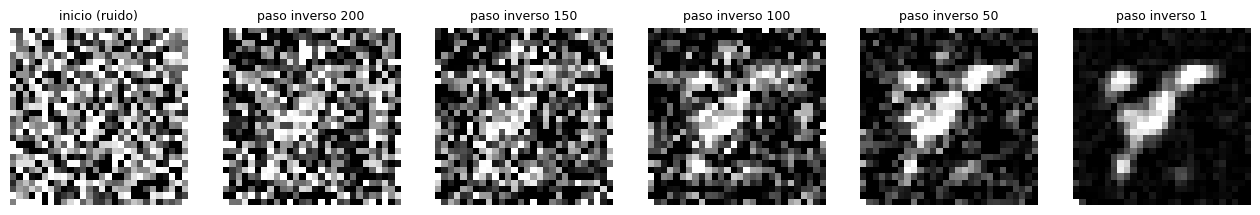

In [9]:
# Evolución de una misma muestra desde ruido hasta una imagen.
# Paso 9. Mostramos los estados guardados de la primera muestra.
fig, axes = plt.subplots(1, len(states), figsize=(16, 3))
for ax, (name, state) in zip(axes, states.items()):
    ax.imshow(np.clip((state[0, :, :, 0] + 1)/2, 0, 1), cmap='gray', vmin=0, vmax=1)
    ax.set_title(name, fontsize=9)
    ax.axis('off')
plt.show()

**Comentario:** Se observa cómo la estructura del dígito aparece poco a poco, sobre todo en los últimos pasos inversos.

## 6. Actividad de verificación: ¿el modelo aprendió a estimar el ruido?

Para una imagen real de MNIST, compara el ruido inyectado con el estimado. Además, recupera $\hat x_0$ mediante

$$\hat x_0=\frac{x_t-\sqrt{1-\bar\alpha_t}\,\epsilon_\theta(x_t,t)}{\sqrt{\bar\alpha_t}}.$$

Esto no es el muestreo generativo completo: es una estimación de imagen limpia a partir de un estado $x_t$ dado.

MAE estimación de ruido: 0.2004


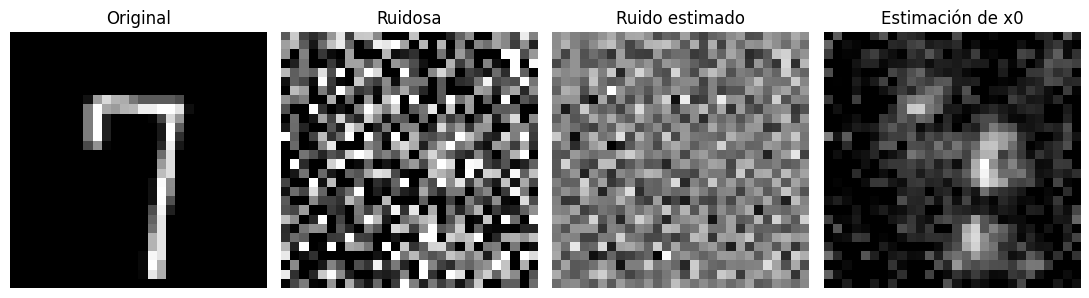

In [10]:
# Paso 10. Tomamos una imagen real y le añadimos ruido en el paso T/3.
clean = x0[:1]
idx = T // 3
t = tf.constant([idx], dtype=tf.int32)
eps = tf.random.normal(tf.shape(clean))
xt = q_sample(clean, t, eps)
# La red estima el ruido sin conocer el real.
eps_hat = model(xt, t, training=False)
ab = extract(alpha_bars, t)
# Despejamos la imagen limpia desde x_t y el ruido estimado.
x0_hat = (xt - tf.sqrt(1.0 - ab) * eps_hat) / tf.sqrt(ab)
# Error absoluto medio: cuanto más bajo, mejor estimó el ruido.
mae_eps = float(tf.reduce_mean(tf.abs(eps - eps_hat)))
print('MAE estimación de ruido:', round(mae_eps, 4))
fig, axs = plt.subplots(1, 4, figsize=(11, 3))
for ax, img, title in zip(axs, [clean, xt, eps_hat, x0_hat],
                           ['Original', 'Ruidosa', 'Ruido estimado', 'Estimación de x0']):
    arr = img[0, :, :, 0].numpy()
    if title in ['Original', 'Ruidosa', 'Estimación de x0']:
        arr = np.clip((arr + 1)/2, 0, 1)
    ax.imshow(arr, cmap='gray'); ax.set_title(title); ax.axis('off')
plt.tight_layout(); plt.show()

**Comentario:** Esta prueba usa una imagen real con ruido; no es generación. Sirve para comprobar que la red aprendió a separar ruido y señal en un paso intermedio.

## 7. Experimentos y preguntas para entregar


**Capacidad:** modifique `base=32` a `base=16` o `base=64`; (bottleneck de la U-NET). Compare parámetros, pérdida y diversidad visual de lo obtenido en generación

**Tiempo de entrenamiento:** contraste más épocas bajo el mismo subconjunto y semilla. Registra MSE y resultados visuales.


**Entregable:**
notebook ejecutado + evidencia de resultados y conclusiones sobre el ejercicio.

**Bono** Intente condicionar el modelo (añadir embedding de número a generar) y estudiar si se pueden generar dígitos solicitados. Puede condicionar a generar solo 3 dígitos, no olvide cambiar el conjunto de entrenamiento.

## 7.1 Preparación de los experimentos

Para que la comparación sea justa, todos los modelos parten de la misma semilla y generan sus muestras desde el mismo ruido inicial.

Además de ver las imágenes, se entrena un clasificador auxiliar de dígitos sobre MNIST. Con él se mide:
- **Clases distintas y entropía:** diversidad de los dígitos generados. El máximo de entropía con 10 clases es 2.30.
- **Confianza media:** qué tan claro le resulta cada dígito al clasificador.
- **Accuracy:** en el bono, si se generó el dígito solicitado.

Estas medidas son aproximadas: un clasificador no reemplaza la inspección visual.

In [11]:
import pandas as pd
from IPython.display import display

# Parámetros de los experimentos: se pueden reducir si la sesión de Colab va lenta.
EPOCAS_CAPACIDAD = 15
BASES = [16, 32, 64]            # Deben ser múltiplos de 8 por GroupNormalization(groups=8).
PUNTOS_EPOCAS = [5, 15, 30]
EPOCAS_BONO = 20
DIGITOS_BONO = [1, 3, 8]
N_MUESTRAS = 256
N_POR_DIGITO = 100

COLORES = ['#2a78d6', '#eb6834', '#1baf7a']
MARCADORES = ['o', 's', '^']

# Mismo ruido inicial para todos los modelos: las diferencias vienen del modelo, no del azar.
ruido_fijo = np.random.default_rng(SEED).standard_normal((N_MUESTRAS, 28, 28, 1)).astype('float32')

# Cargamos MNIST completo: el clasificador y el bono usan más datos que el subconjunto inicial.
def normalizar(imagenes):
    return (imagenes.astype('float32') / 127.5 - 1.0)[..., None]

(imagenes_completas, etiquetas_completas), (imagenes_prueba, etiquetas_prueba) = keras.datasets.mnist.load_data()
imagenes_completas, imagenes_prueba = normalizar(imagenes_completas), normalizar(imagenes_prueba)

# Clasificador auxiliar: solo se usa para evaluar las muestras generadas.
keras.utils.set_random_seed(SEED)
clasificador = keras.Sequential([
    keras.Input((28, 28, 1)),
    layers.Conv2D(32, 3, activation='relu'), layers.MaxPooling2D(),
    layers.Conv2D(64, 3, activation='relu'), layers.MaxPooling2D(),
    layers.Flatten(), layers.Dense(10, activation='softmax')])
clasificador.compile(optimizer='adam', loss='sparse_categorical_crossentropy', metrics=['accuracy'])
clasificador.fit(imagenes_completas, etiquetas_completas, epochs=3, batch_size=256, verbose=0)
_, accuracy_clasificador = clasificador.evaluate(imagenes_prueba, etiquetas_prueba, verbose=0)
print(f'Accuracy del clasificador en prueba: {accuracy_clasificador:.4f}')

Accuracy del clasificador en prueba: 0.9838


In [12]:
# Crea un paso de entrenamiento propio para cada modelo (misma lógica de la sección 4).
def crear_paso(red, optimizador):
    @tf.function
    def paso(limpias):
        t = tf.random.uniform([tf.shape(limpias)[0]], minval=0, maxval=T, dtype=tf.int32)
        ruido = tf.random.normal(tf.shape(limpias))
        ruidosas = q_sample(limpias, t, ruido)
        with tf.GradientTape() as cinta:
            perdida = tf.reduce_mean(tf.square(red(ruidosas, t, training=True) - ruido))
        gradientes = cinta.gradient(perdida, red.trainable_variables)
        optimizador.apply_gradients(zip(gradientes, red.trainable_variables))
        return perdida
    return paso

# Entrena n_epocas y devuelve el MSE promedio de cada una.
def entrenar_epocas(paso, n_epocas):
    historial = []
    for _ in range(n_epocas):
        total, vistos = 0.0, 0
        for limpias in train_ds:
            n = int(tf.shape(limpias)[0])
            total += float(paso(limpias)) * n
            vistos += n
        historial.append(total / vistos)
    return historial

# Proceso inverso completo (sección 5). predecir(x, t) devuelve el ruido estimado.
def muestrear(predecir, ruido_inicial):
    tf.random.set_seed(SEED)  # Mismo azar en cada paso inverso para todos los modelos.
    predecir = tf.function(predecir)
    x = tf.constant(ruido_inicial)
    for indice in reversed(range(T)):
        t = tf.fill([tf.shape(x)[0]], indice)
        beta_t, alpha_t, ab_t = extract(betas, t), extract(alphas, t), extract(alpha_bars, t)
        x_media = (x - beta_t / tf.sqrt(1.0 - ab_t) * predecir(x, t)) / tf.sqrt(alpha_t)
        x = x_media if indice == 0 else (
            x_media + tf.sqrt(extract(posterior_variance, t)) * tf.random.normal(tf.shape(x)))
    return np.clip(x.numpy(), -1.0, 1.0)

# Resume las muestras con el clasificador: diversidad y claridad de los dígitos.
def medir_muestras(muestras):
    probabilidades = clasificador.predict(muestras, batch_size=256, verbose=0)
    frecuencias = np.bincount(probabilidades.argmax(axis=1), minlength=10) / len(muestras)
    presentes = frecuencias[frecuencias > 0]
    return {'Clases distintas': len(presentes),
            'Entropía': round(float(-(presentes * np.log(presentes)).sum()), 3),
            'Confianza media': round(float(probabilidades.max(axis=1).mean()), 3)}

# Una fila de imágenes por cada configuración, generadas desde el mismo ruido.
def mostrar_filas(filas, n=12):
    fig, axs = plt.subplots(len(filas), n, figsize=(n, 1.25 * len(filas)), squeeze=False)
    for fila, (titulo, muestras) in zip(axs, filas.items()):
        for ax, muestra in zip(fila, muestras):
            ax.imshow((muestra[:, :, 0] + 1) / 2, cmap='gray', vmin=0, vmax=1)
            ax.set_xticks([]); ax.set_yticks([])
            for borde in ax.spines.values():
                borde.set_visible(False)
        fila[0].set_ylabel(titulo, rotation=0, ha='right', va='center', fontsize=9)
    plt.tight_layout(); plt.show()

# Formato común de las gráficas de pérdida.
def formato_perdida(ax, titulo):
    ax.set_title(titulo, loc='left'); ax.set_xlabel('Época'); ax.set_ylabel('MSE de predicción de ruido')
    ax.grid(axis='y', alpha=.3)
    ax.spines['top'].set_visible(False); ax.spines['right'].set_visible(False)

## 7.2 Experimento 1: capacidad del modelo

Se entrena la misma red con `base=16`, `base=32` y `base=64`, con iguales datos, semilla y épocas. Solo cambia el número de filtros. Se comparan parámetros, pérdida, tiempo y diversidad visual.

In [13]:
filas_capacidad, curvas_capacidad, muestras_capacidad = [], {}, {}

for base in BASES:
    # Reiniciamos la semilla para que todos partan de las mismas condiciones.
    keras.utils.set_random_seed(SEED)
    red = SmallUNet(base=base)
    red(tf.zeros([1, 28, 28, 1]), tf.zeros([1], tf.int32))  # Crea los pesos para poder contarlos.
    inicio = time.time()
    curva = entrenar_epocas(crear_paso(red, keras.optimizers.Adam(learning_rate=LR)), EPOCAS_CAPACIDAD)
    minutos = (time.time() - inicio) / 60
    muestras = muestrear(lambda x, t: red(x, t, training=False), ruido_fijo)
    curvas_capacidad[base], muestras_capacidad[f'base={base}'] = curva, muestras
    filas_capacidad.append({'base': base, 'Parámetros': red.count_params(), 'MSE final': round(curva[-1], 4),
                            'Tiempo (min)': round(minutos, 2), **medir_muestras(muestras)})
    print(f'base={base}: MSE final {curva[-1]:.4f} en {minutos:.1f} min')

tabla_capacidad = pd.DataFrame(filas_capacidad)
display(tabla_capacidad)

base=16: MSE final 0.0604 en 1.1 min
base=32: MSE final 0.0470 en 1.7 min
base=64: MSE final 0.0569 en 3.2 min


,base,Parámetros,MSE final,Tiempo (min),Clases distintas,Entropía,Confianza media
0,16,119521,0.0604,1.09,10,1.817,0.698
1,32,372417,0.0470,1.69,10,2.026,0.734
2,64,1352833,0.0569,3.24,7,1.631,0.705


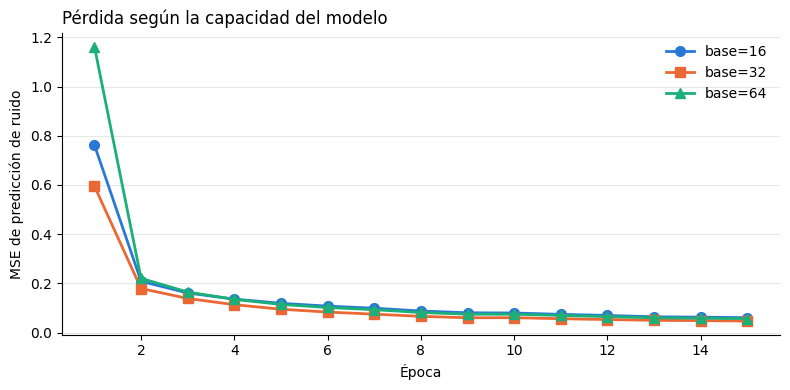

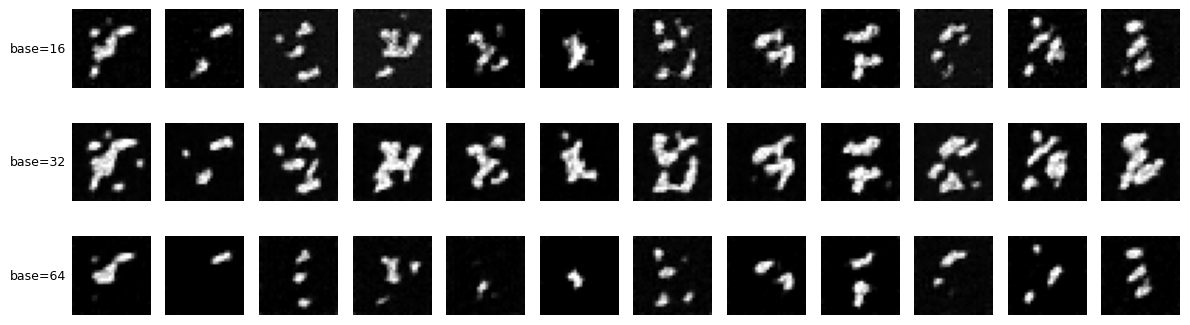

In [14]:
# Curvas de pérdida: cada capacidad con color y marcador propios.
fig, ax = plt.subplots(figsize=(8, 4))
for i, (base, curva) in enumerate(curvas_capacidad.items()):
    ax.plot(range(1, len(curva) + 1), curva, color=COLORES[i], marker=MARCADORES[i],
            markersize=7, linewidth=2, label=f'base={base}')
formato_perdida(ax, 'Pérdida según la capacidad del modelo')
ax.legend(frameon=False); plt.tight_layout(); plt.show()

# Mismo ruido inicial en cada columna: facilita comparar los resultados.
mostrar_filas(muestras_capacidad)

## 7.3 Experimento 2: tiempo de entrenamiento

Se entrena un solo modelo con `base=32` hasta 30 épocas, con el mismo subconjunto y semilla. Se detiene a generar muestras en las épocas 5, 15 y 30; así las tres comparaciones pertenecen al mismo entrenamiento.

In [15]:
keras.utils.set_random_seed(SEED)
red_tiempo = SmallUNet(base=32)
paso_tiempo = crear_paso(red_tiempo, keras.optimizers.Adam(learning_rate=LR))

curva_tiempo, filas_tiempo, muestras_tiempo = [], [], {}
minutos, epoca_actual = 0.0, 0
for epoca_objetivo in PUNTOS_EPOCAS:
    # Continuamos entrenando el mismo modelo hasta el siguiente punto de control.
    inicio = time.time()
    curva_tiempo += entrenar_epocas(paso_tiempo, epoca_objetivo - epoca_actual)
    minutos += (time.time() - inicio) / 60  # Solo cuenta entrenamiento, no la generación.
    epoca_actual = epoca_objetivo
    muestras = muestrear(lambda x, t: red_tiempo(x, t, training=False), ruido_fijo)
    # Muestrear usa una semilla fija; la cambiamos para no repetir el mismo azar al seguir entrenando.
    tf.random.set_seed(SEED + epoca_objetivo)
    muestras_tiempo[f'{epoca_objetivo} épocas'] = muestras
    filas_tiempo.append({'Épocas': epoca_objetivo, 'MSE': round(curva_tiempo[-1], 4),
                         'Tiempo acumulado (min)': round(minutos, 2), **medir_muestras(muestras)})
    print(f'{epoca_objetivo} épocas: MSE {curva_tiempo[-1]:.4f}')

tabla_tiempo = pd.DataFrame(filas_tiempo)
display(tabla_tiempo)

5 épocas: MSE 0.0950
15 épocas: MSE 0.0488
30 épocas: MSE 0.0361


,Épocas,MSE,Tiempo acumulado (min),Clases distintas,Entropía,Confianza media
0,5,0.0950,0.70,10,1.897,0.699
1,15,0.0488,1.68,10,2.008,0.730
2,30,0.0361,3.28,10,1.962,0.757


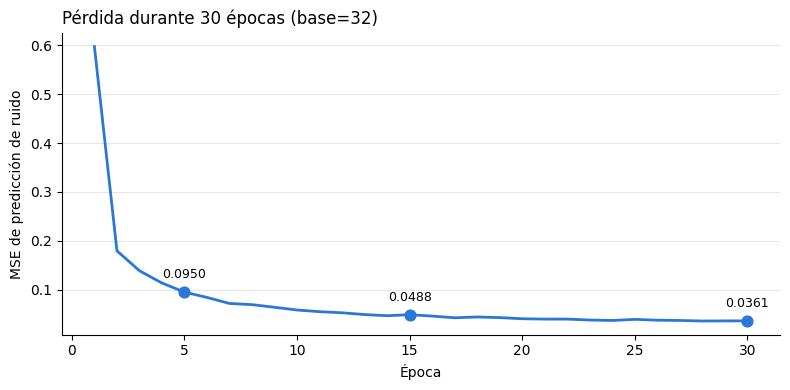

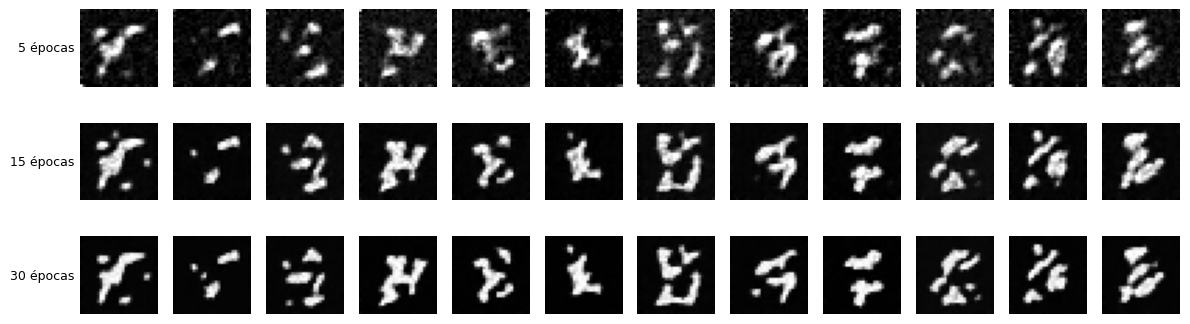

In [16]:
fig, ax = plt.subplots(figsize=(8, 4))
ax.plot(range(1, len(curva_tiempo) + 1), curva_tiempo, color=COLORES[0], linewidth=2)
# Marcamos los puntos donde se generaron muestras.
puntos_y = [curva_tiempo[p - 1] for p in PUNTOS_EPOCAS]
ax.scatter(PUNTOS_EPOCAS, puntos_y, color=COLORES[0], s=60, zorder=3)
for x, y in zip(PUNTOS_EPOCAS, puntos_y):
    ax.annotate(f'{y:.4f}', (x, y), textcoords='offset points', xytext=(0, 10), ha='center', fontsize=9)
formato_perdida(ax, 'Pérdida durante 30 épocas (base=32)')
plt.tight_layout(); plt.show()

mostrar_filas(muestras_tiempo)

## 7.4 Bono: generar el dígito solicitado

Se interpreta el enunciado como entrenar con **solo tres clases de dígitos** (por defecto 1, 3 y 8; se cambian en `DIGITOS_BONO`).

Cambios frente al modelo original:
1. **Datos:** se filtra MNIST completo para dejar solo esos dígitos, y cada imagen conserva su etiqueta.
2. **Modelo:** el dígito se convierte en un vector aprendido y se suma al del tiempo, así llega a todos los bloques residuales.
3. **Generación:** se indica qué dígito se quiere y el clasificador auxiliar comprueba si se obtuvo.

Imágenes de entrenamiento para el bono: 18724
MSE final: 0.0327 | Tiempo: 3.3 min


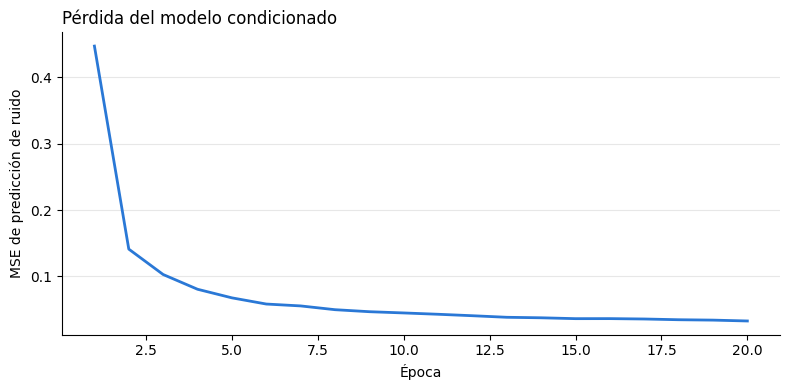

In [17]:
# Datos: solo los dígitos elegidos, con etiquetas 0, 1, 2 para el vector aprendido.
mascara = np.isin(etiquetas_completas, DIGITOS_BONO)
imagenes_bono = imagenes_completas[mascara]
etiquetas_bono = np.searchsorted(DIGITOS_BONO, etiquetas_completas[mascara]).astype('int32')
datos_bono = (tf.data.Dataset.from_tensor_slices((imagenes_bono, etiquetas_bono))
              .shuffle(len(imagenes_bono), seed=SEED, reshuffle_each_iteration=True)
              .batch(BATCH_SIZE).prefetch(AUTOTUNE))
print('Imágenes de entrenamiento para el bono:', len(imagenes_bono))

# Modelo: igual a SmallUNet, pero con información del dígito sumada a la del tiempo.
class UNetCondicional(SmallUNet):
    def __init__(self, num_clases, base=32, time_dim=128):
        super().__init__(base=base, time_dim=time_dim)
        self.vector_digito = layers.Embedding(num_clases, time_dim)

    def call(self, x, t, y, training=False):
        emb = self.time_mlp(t) + self.vector_digito(y)
        h0 = self.init_conv(x)
        h1 = self.down1(h0, emb)
        h2 = self.down2(self.downsample1(h1), emb)
        hm = self.mid(self.downsample2(h2), emb)
        u2 = tf.image.resize(hm, tf.shape(h2)[1:3], method='nearest')
        u2 = self.up2(tf.concat([u2, h2], axis=-1), emb)
        u1 = tf.image.resize(u2, tf.shape(h1)[1:3], method='nearest')
        return self.out_conv(self.up1(tf.concat([u1, h1], axis=-1), emb))

keras.utils.set_random_seed(SEED)
red_bono = UNetCondicional(num_clases=len(DIGITOS_BONO))
optimizador_bono = keras.optimizers.Adam(learning_rate=LR)

# Entrenamiento: igual al original, pero la red también recibe la etiqueta.
@tf.function
def paso_bono(limpias, etiquetas):
    t = tf.random.uniform([tf.shape(limpias)[0]], minval=0, maxval=T, dtype=tf.int32)
    ruido = tf.random.normal(tf.shape(limpias))
    ruidosas = q_sample(limpias, t, ruido)
    with tf.GradientTape() as cinta:
        perdida = tf.reduce_mean(tf.square(red_bono(ruidosas, t, etiquetas, training=True) - ruido))
    gradientes = cinta.gradient(perdida, red_bono.trainable_variables)
    optimizador_bono.apply_gradients(zip(gradientes, red_bono.trainable_variables))
    return perdida

curva_bono = []
inicio = time.time()
for epoca in range(EPOCAS_BONO):
    total, vistos = 0.0, 0
    for limpias, etiquetas in datos_bono:
        n = int(tf.shape(limpias)[0])
        total += float(paso_bono(limpias, etiquetas)) * n
        vistos += n
    curva_bono.append(total / vistos)
print(f'MSE final: {curva_bono[-1]:.4f} | Tiempo: {(time.time() - inicio) / 60:.1f} min')

fig, ax = plt.subplots(figsize=(8, 4))
ax.plot(range(1, len(curva_bono) + 1), curva_bono, color=COLORES[0], linewidth=2)
formato_perdida(ax, 'Pérdida del modelo condicionado')
plt.tight_layout(); plt.show()

,Dígito solicitado,Accuracy,Confianza media
0,1,0.14,0.706
1,3,0.18,0.761
2,8,0.42,0.762


Accuracy promedio: 0.247


,Reconocido: 0,Reconocido: 1,Reconocido: 2,Reconocido: 3,Reconocido: 4,Reconocido: 5,Reconocido: 6,Reconocido: 7,Reconocido: 8,Reconocido: 9
Pedido: 1,1,14,12,23,1,32,2,13,0,2
Pedido: 3,0,5,12,18,0,24,0,3,37,1
Pedido: 8,0,4,12,16,0,23,0,3,42,0


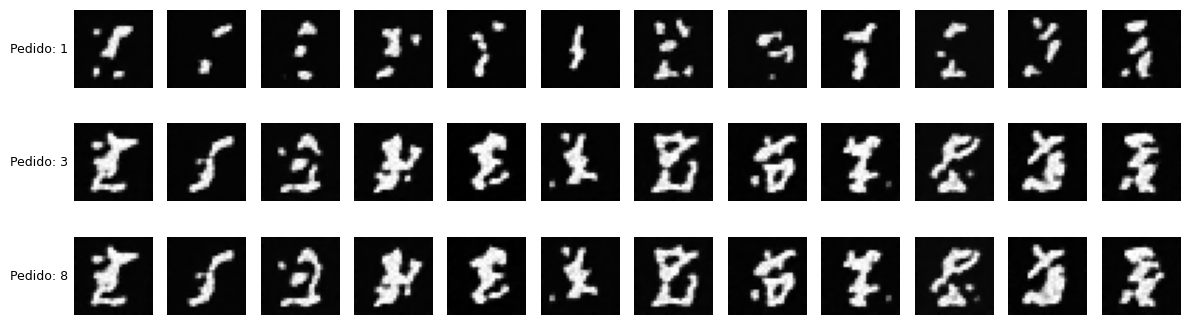

In [18]:
# Pedimos N_POR_DIGITO imágenes de cada dígito y revisamos cuál reconoce el clasificador.
ruido_bono = np.random.default_rng(SEED + 1).standard_normal((N_POR_DIGITO, 28, 28, 1)).astype('float32')
filas_bono, muestras_bono, conteos = [], {}, {}

for indice_digito, digito in enumerate(DIGITOS_BONO):
    solicitados = tf.fill([N_POR_DIGITO], indice_digito)
    muestras = muestrear(lambda x, t: red_bono(x, t, solicitados, training=False), ruido_bono)
    probabilidades = clasificador.predict(muestras, batch_size=256, verbose=0)
    predichos = probabilidades.argmax(axis=1)
    muestras_bono[f'Pedido: {digito}'] = muestras
    conteos[f'Pedido: {digito}'] = np.bincount(predichos, minlength=10)
    filas_bono.append({'Dígito solicitado': digito, 'Accuracy': round(float((predichos == digito).mean()), 3),
                       'Confianza media': round(float(probabilidades.max(axis=1).mean()), 3)})

tabla_bono = pd.DataFrame(filas_bono)
display(tabla_bono)
print('Accuracy promedio:', round(float(tabla_bono['Accuracy'].mean()), 3))

# Filas: dígito pedido. Columnas: dígito reconocido por el clasificador.
tabla_conteos = pd.DataFrame(conteos, index=[f'Reconocido: {d}' for d in range(10)]).T
display(tabla_conteos)

# Cada columna parte del mismo ruido: solo cambia el dígito pedido.
mostrar_filas(muestras_bono)

## 8. Resultados y conclusiones

**Pendiente:** esta sección se redacta después de ejecutar el notebook completo en Colab, a partir de las tablas y figuras de las secciones 7.2, 7.3 y 7.4.